In [1]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# Load your cleaned dataset
df = pd.read_csv(
    r"C:\Users\Aparna\Desktop\Assignment\Delhi_Air_Quality_Daily_2025.csv"
)

# Convert date and extract month
df["date"] = pd.to_datetime(df["date"])
df["month"] = df["date"].dt.month

# AQI categories
categories = [
    "Good", "Satisfactory", "Moderately Polluted",
    "Poor", "Very Poor", "Severe"
]

ranges = [
    "0–50", "51–100", "101–200",
    "201–300", "301–400", "401–500"
]

colors = [
    "#009966", "#9CCB4F", "#FFF000",
    "#FFA000", "#EF3833", "#800020"
]

# Additional category for AQI above 500
# Outside the standard Indian AQI category scale
all_colors = colors + ["#555555"]

bounds = [0, 51, 101, 201, 301, 401, 501, np.inf]

aqi_cmap = ListedColormap(all_colors)
aqi_norm = BoundaryNorm(bounds, aqi_cmap.N)

def get_aqi_color(value):
    if pd.isna(value):
        return "#BDBDBD"
    for upper, color in zip(bounds[1:], all_colors):
        if value < upper:
            return color
    return all_colors[-1]

aqi_legend = [
    Patch(facecolor=color, label=f"{cat} ({rng})")
    for cat, rng, color in zip(categories, ranges, colors)
]

aqi_legend.append(
    Patch(facecolor="#555555", label="Above 500 (outside scale)")
)

sns.set_theme(style="whitegrid")

Monthly Average AQI by Location


month,1,2,3,4,5,6,7,8,9,10,11,12
location,,,,,,,,,,,,
Anand Vihar,189.92,153.62,272.14,240.11,270.68,237.07,147.39,179.49,118.34,151.70,175.64,193.16
Connaught Place,189.92,153.62,272.14,240.11,270.68,237.07,147.39,179.49,118.34,151.70,175.64,193.16
Dwarka,188.54,156.22,848.49,843.72,894.84,530.76,148.26,268.45,129.44,161.21,180.09,196.84
IGI Airport,188.54,156.22,848.49,843.72,894.84,530.76,148.26,268.45,129.44,161.21,180.09,196.84
Okhla Phase III,188.54,156.22,848.49,843.72,894.84,530.76,148.26,268.45,129.44,161.21,180.09,196.84
Rohini,189.92,153.62,272.14,240.11,270.68,237.07,147.39,179.49,118.34,151.70,175.64,193.16


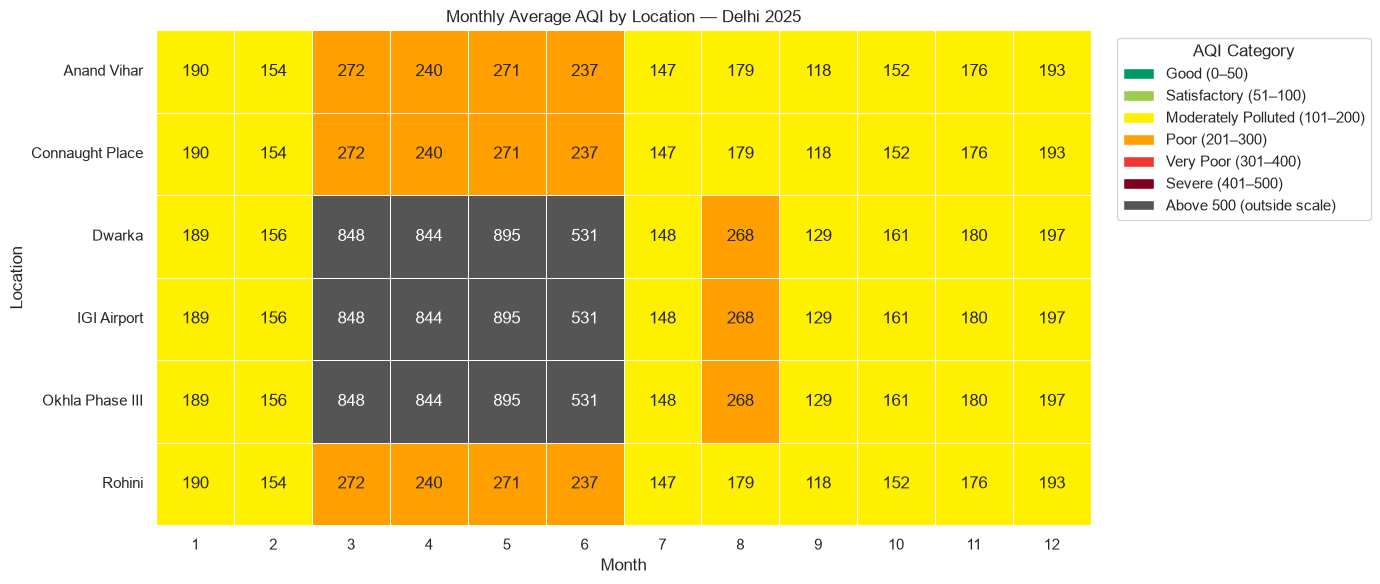

In [12]:
# Calculate monthly average AQI
monthly_aqi = df.groupby(
    ["location", "month"]
)["aqi_index"].mean().reset_index()

# Convert to heatmap table
heatmap_data = monthly_aqi.pivot(
    index="location",
    columns="month",
    values="aqi_index"
)

# Display data table
print("Monthly Average AQI by Location")
display(heatmap_data.round(2))

# Create heatmap
plt.figure(figsize=(14, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap=aqi_cmap,
    norm=aqi_norm,
    linewidths=0.5,
    linecolor="white",
    cbar=False
)

plt.title("Monthly Average AQI by Location — Delhi 2025")
plt.xlabel("Month")
plt.ylabel("Location")

plt.legend(
    handles=aqi_legend,
    title="AQI Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

categories = [
    "Good",
    "Satisfactory",
    "Moderately Polluted",
    "Poor",
    "Very Poor",
    "Severe"
]

colors = [
    "#009966",  # Good
    "#9CCB4F",  # Satisfactory
    "#FFF000",  # Moderately Polluted
    "#FFA000",  # Poor
    "#EF3833",  # Very Poor
    "#800020"   # Severe
]

# Upper boundaries for each pollutant
breakpoints = {
    "pm2_5": [30, 60, 90, 120, 250, np.inf],
    "pm10": [50, 100, 250, 350, 430, np.inf],
    "no2": [40, 80, 180, 280, 400, np.inf],
    "co": [1, 2, 10, 17, 34, np.inf]
}

def get_pollutant_category(value, pollutant):
    if pd.isna(value) or value < 0:
        return "Unknown"

    for i, upper in enumerate(breakpoints[pollutant]):
        if value <= upper:
            return categories[i]

def get_pollutant_color(value, pollutant):
    category = get_pollutant_category(value, pollutant)

    if category == "Unknown":
        return "#BDBDBD"

    return colors[categories.index(category)]

,aqi_index,pm2_5,pm10,co,no2
location,,,,,
Anand Vihar,194.45,80.31,199.17,935.08,33.86
Connaught Place,194.45,80.31,199.17,865.33,33.86
Dwarka,380.28,98.77,401.75,806.03,37.02
IGI Airport,380.28,98.77,401.75,859.42,37.02
Okhla Phase III,380.28,98.77,401.75,898.26,37.02
Rohini,194.45,80.31,199.17,818.95,33.86


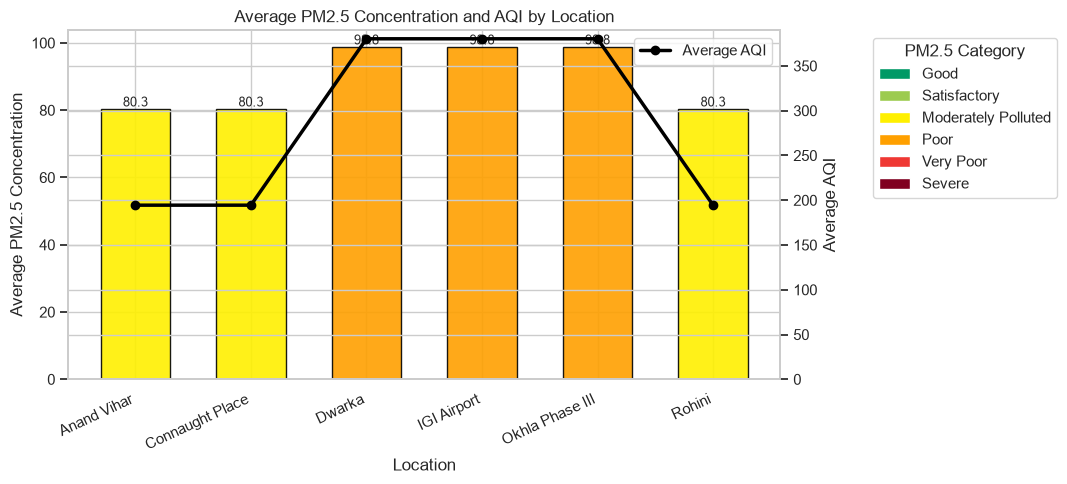

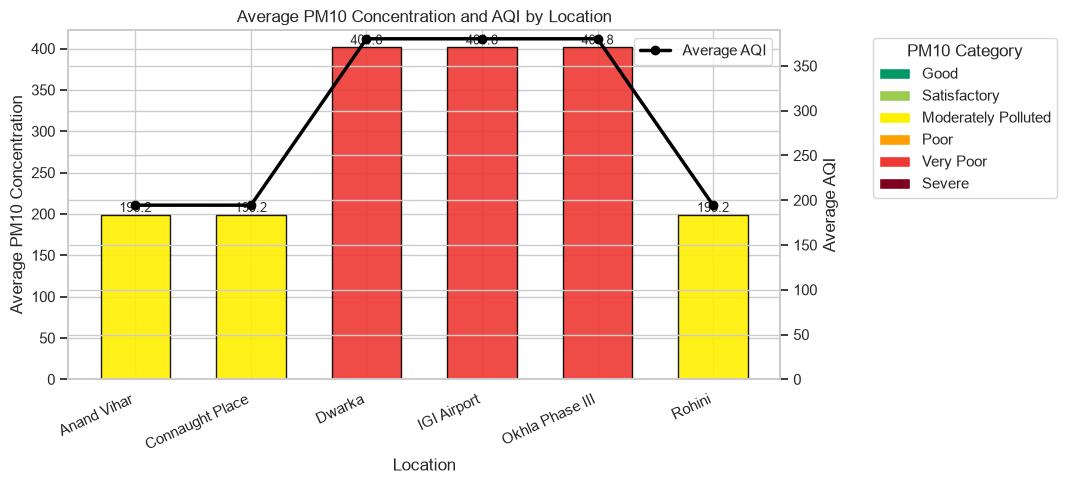

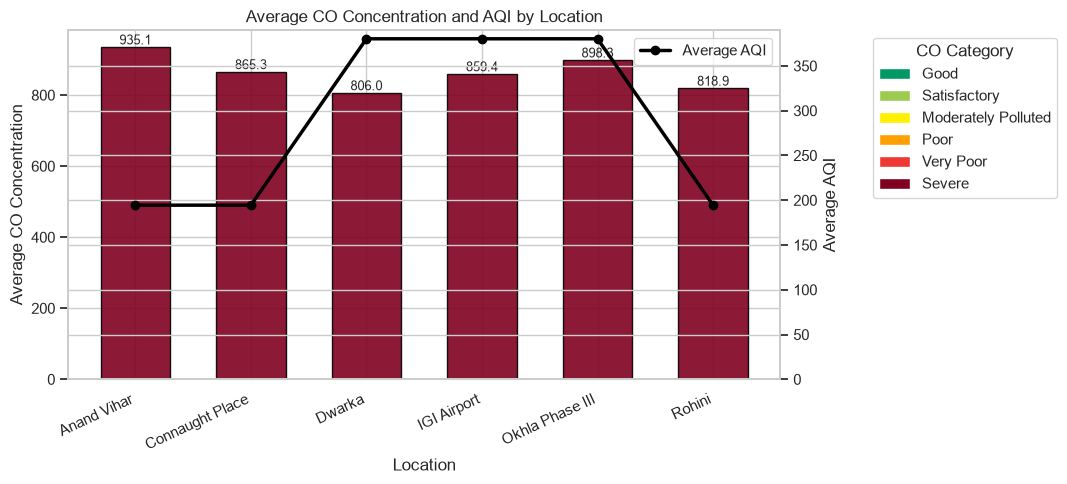

C:\Users\Aparna\AppData\Local\Temp\ipykernel_2688\1375011444.py:95: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\Aparna\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


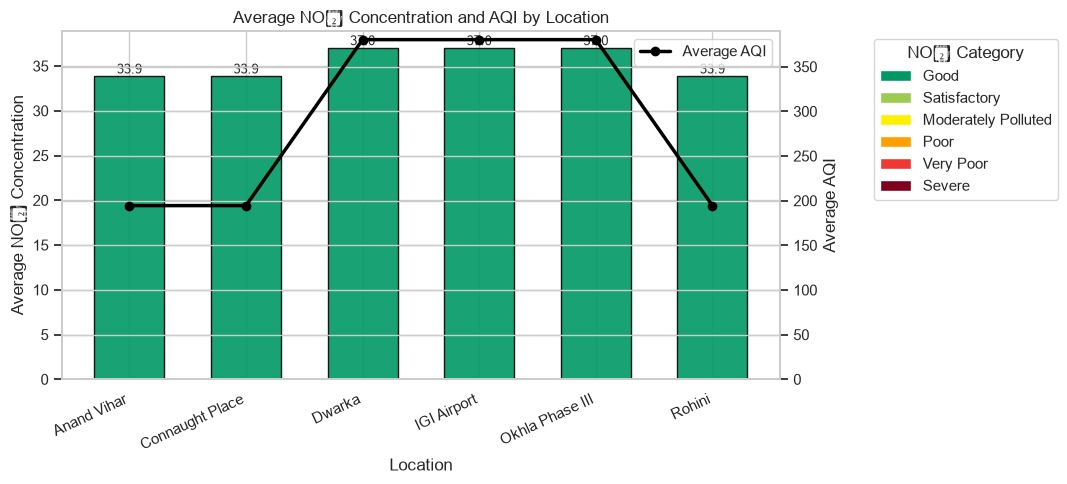

In [14]:
pollutants = {
    "pm2_5": "PM2.5",
    "pm10": "PM10",
    "co": "CO",
    "no2": "NO₂"
}

# Average pollutant and AQI by location
location_avg = df.groupby("location")[
    ["aqi_index"] + list(pollutants.keys())
].mean()

display(location_avg.round(2))

# Generate four separate charts
for pollutant, label in pollutants.items():

    fig, ax1 = plt.subplots(figsize=(11, 5))

    locations = location_avg.index
    x = np.arange(len(locations))

    # Color bars based on pollutant concentration
    bar_colors = [
        get_pollutant_color(value, pollutant)
        for value in location_avg[pollutant]
    ]

    bars = ax1.bar(
        x,
        location_avg[pollutant],
        color=bar_colors,
        edgecolor="black",
        width=0.6,
        alpha=0.9
    )

    ax1.set_ylabel(f"Average {label} Concentration")
    ax1.set_xlabel("Location")
    ax1.set_xticks(x)
    ax1.set_xticklabels(
        locations,
        rotation=25,
        ha="right"
    )
    ax1.set_ylim(bottom=0)

    # Add concentration labels
    for bar in bars:
        height = bar.get_height()

        ax1.text(
            bar.get_x() + bar.get_width() / 2,
            height,
            f"{height:.1f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

    # Secondary axis for AQI
    ax2 = ax1.twinx()

    ax2.plot(
        x,
        location_avg["aqi_index"],
        color="black",
        marker="o",
        linewidth=2.5,
        label="Average AQI"
    )

    ax2.set_ylabel("Average AQI")
    ax2.set_ylim(bottom=0)

    # Pollutant-specific legend
    legend_items = [
        Patch(facecolor=color, label=category)
        for category, color in zip(categories, colors)
    ]

    ax1.legend(
        handles=legend_items,
        title=f"{label} Category",
        bbox_to_anchor=(1.12, 1),
        loc="upper left"
    )

    ax2.legend(loc="upper right")

    plt.title(
        f"Average {label} Concentration and AQI by Location"
    )

    plt.tight_layout()
    plt.show()

Pollutant Correlation with AQI


,aqi_index
pm10,0.930
pm2_5,0.623
co,-0.200
no2,-0.261


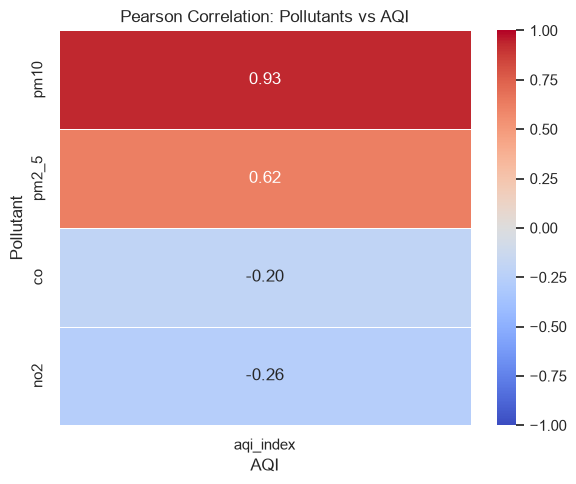

In [15]:
pollutant_cols = ["pm2_5", "pm10", "co", "no2"]

# Calculate Pearson correlations
corr = df[
    ["aqi_index"] + pollutant_cols
].corr(method="pearson")

# Extract correlations with AQI
aqi_pollutant_corr = (
    corr.loc[pollutant_cols, ["aqi_index"]]
    .sort_values("aqi_index", ascending=False)
)

print("Pollutant Correlation with AQI")
display(aqi_pollutant_corr.round(3))

plt.figure(figsize=(6, 5))

sns.heatmap(
    aqi_pollutant_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Pearson Correlation: Pollutants vs AQI")
plt.xlabel("AQI")
plt.ylabel("Pollutant")

plt.tight_layout()
plt.show()

Weather Correlation with AQI


,aqi_index
windspeed_kph,0.330
temp_c,0.225
pressure_mb,-0.148
humidity,-0.414


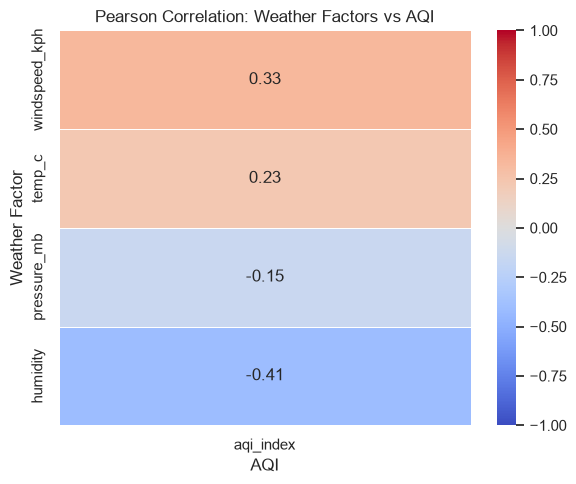

In [16]:
weather_cols = [
    "temp_c",
    "humidity",
    "pressure_mb",
    "windspeed_kph"
]

# Calculate correlations
weather_corr = df[
    ["aqi_index"] + weather_cols
].corr(method="pearson")

# Extract correlations with AQI
aqi_weather_corr = (
    weather_corr.loc[weather_cols, ["aqi_index"]]
    .sort_values("aqi_index", ascending=False)
)

print("Weather Correlation with AQI")
display(aqi_weather_corr.round(3))

plt.figure(figsize=(6, 5))

sns.heatmap(
    aqi_weather_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Pearson Correlation: Weather Factors vs AQI")
plt.xlabel("AQI")
plt.ylabel("Weather Factor")

plt.tight_layout()
plt.show()

,count,mean,median,min,max
location,,,,,
IGI Airport,365,380.28,179.12,58.96,2443.79
Dwarka,365,380.28,179.12,58.96,2443.79
Okhla Phase III,365,380.28,179.12,58.96,2443.79
Anand Vihar,365,194.45,165.79,63.62,726.46
Connaught Place,365,194.45,165.79,63.62,726.46
Rohini,365,194.45,165.79,63.62,726.46


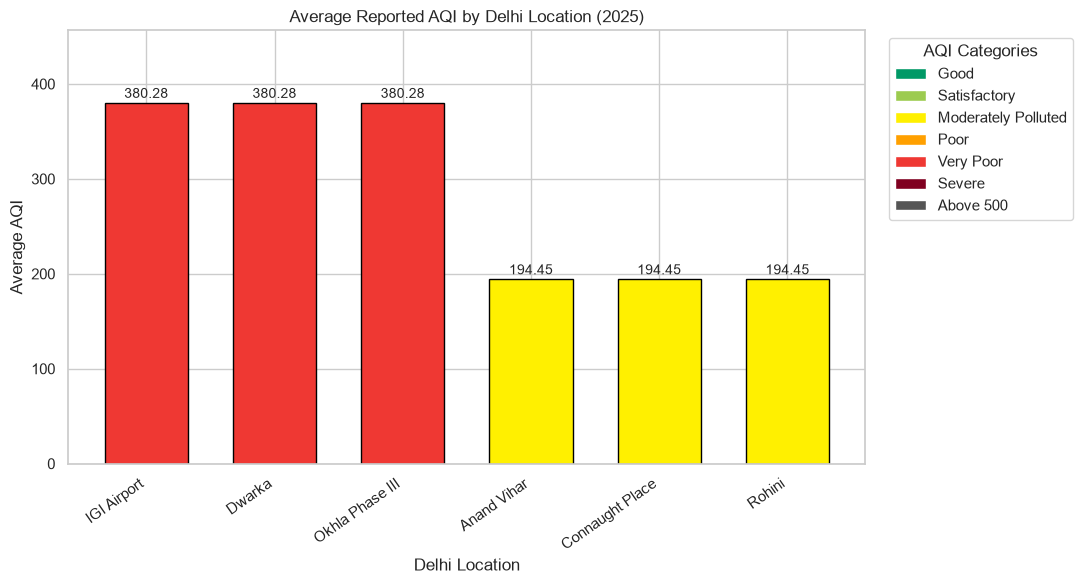

In [18]:
from matplotlib.patches import Patch

# 1. Calculate AQI summary by location
summary = (
    df.groupby("location")["aqi_index"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
    .sort_values("mean", ascending=False)
)

display(summary)

# 2. AQI category colors (same as heatmap)
categories = [
    "Good",
    "Satisfactory",
    "Moderately Polluted",
    "Poor",
    "Very Poor",
    "Severe",
    "Above 500"
]

colors = [
    "#009966",
    "#9CCB4F",
    "#FFF000",
    "#FFA000",
    "#EF3833",
    "#800020",
    "#555555"
]

# 3. Assign color based on average AQI
def get_aqi_color(aqi):
    if aqi <= 50:
        return colors[0]
    elif aqi <= 100:
        return colors[1]
    elif aqi <= 200:
        return colors[2]
    elif aqi <= 300:
        return colors[3]
    elif aqi <= 400:
        return colors[4]
    elif aqi <= 500:
        return colors[5]
    else:
        return colors[6]

bar_colors = [
    get_aqi_color(value)
    for value in summary["mean"]
]

# 4. Create bar chart
plt.figure(figsize=(11, 6))

bars = plt.bar(
    summary.index,
    summary["mean"],
    color=bar_colors,
    edgecolor="black",
    width=0.65
)

# 5. Display AQI values above bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 5,
        f"{height:.2f}",
        ha="center",
        fontsize=10
    )

plt.xticks(rotation=35, ha="right")
plt.xlabel("Delhi Location")
plt.ylabel("Average AQI")
plt.title("Average Reported AQI by Delhi Location (2025)")

plt.ylim(0, summary["mean"].max() * 1.2)

# 6. Add AQI category legend
legend_items = [
    Patch(facecolor=color, label=category)
    for category, color in zip(categories, colors)
]

plt.legend(
    handles=legend_items,
    title="AQI Categories",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()